# Lab Program 06: Bidirectional LSTM with Attention for Sentiment Analysis

## Aim
To implement a Bidirectional LSTM with an Attention mechanism using the IMDB movie review dataset to classify reviews as positive or negative.

## Introduction

### 1. Sentiment Analysis
Sentiment analysis is an essential Natural Language Processing (NLP) task that automatically determines the emotional polarity (positive or negative) of a given text. It is widely employed in opinion mining, customer feedback analysis, and movie/product review classification.

### 2. Long Short-Term Memory (LSTM)
Standard Recurrent Neural Networks (RNNs) struggle with long sequence dependencies due to vanishing/exploding gradient problems. LSTMs introduce dedicated memory cells controlled by three gating units:
- **Forget Gate:** Decides what prior context to discard.
- **Input Gate:** Selects which new information to store in the memory cell.
- **Output Gate:** Regulates which parts of the memory cell state to output as the hidden state.

### 3. Bidirectional LSTM (BiLSTM)
Standard LSTMs process sequences in a single direction (left to right / past to future). A **Bidirectional LSTM** trains two parallel LSTM layers: one reading forward and one reading backward. Combining both states at each time step gives the model access to past and future context simultaneously.

### 4. Attention Mechanism
Rather than compressing an entire review sequence into an unweighted static vector, the **Attention mechanism** calculates dynamic alignment scores. It assigns higher weights to the most sentiment-informative words (such as *"masterpiece"*, *"terrible"*, *"horrible"*, *"exceptional"*), significantly improving classification accuracy and model interpretability.

### Step 1: Import Libraries
We import TensorFlow, NumPy, Keras layers, plotting libraries (Matplotlib, Seaborn), and evaluation metrics from Scikit-Learn.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Bidirectional,
    Dense, Attention, GlobalAveragePooling1D
)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print("All required libraries successfully imported.")

TensorFlow Version: 2.21.0
All required libraries successfully imported.


### Step 2: Load Real-World IMDB Dataset
The IMDB dataset contains 50,000 movie reviews labeled as 0 (negative) or 1 (positive). We restrict the vocabulary size to the top 10,000 most frequent words.

In [2]:
vocab_size = 10000
max_length = 100

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

print(f"Training reviews: {len(X_train)}")
print(f"Testing reviews:  {len(X_test)}")
print(f"Vocabulary size:  {vocab_size}")

# Helper dictionary to decode integer sequences back into human-readable text
word_index = imdb.get_word_index()
reverse_word_index = {value + 3: key for key, value in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

def decode_review(token_list):
    return " ".join([reverse_word_index.get(i, "?") for i in token_list])

print("\nSample Raw Review (first 10 tokens):", X_train[0][:10])
print("\nSample Decoded Training Review:")
print(decode_review(X_train[0])[:250] + "...")
print(f"Sentiment Label: {y_train[0]} ({'Positive' if y_train[0] == 1 else 'Negative'})")

Training reviews: 25000
Testing reviews:  25000
Vocabulary size:  10000

Sample Raw Review (first 10 tokens): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65]

Sample Decoded Training Review:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from...
Sentiment Label: 1 (Positive)


### Step 3: Padding Sequences
Reviews differ in length. We standardize all sequences to a fixed length of 100 tokens using `pad_sequences`.

In [3]:
# Padding sequences
X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

print("Preprocessed Dataset Shapes:")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_test shape:  {y_test.shape}")

Preprocessed Dataset Shapes:
X_train shape: (25000, 100)
y_train shape: (25000,)
X_test shape:  (25000, 100)
y_test shape:  (25000,)


### Steps 4 – 10: Define Layers & Build the BiLSTM-Attention Model
We construct the deep network using the Keras Functional API:
1. **Input Layer (Step 4):** Accepts integer sequences of shape `(100,)`.
2. **Embedding Layer (Step 5):** Maps discrete tokens to 64-dimensional dense vectors.
3. **Bidirectional LSTM (Step 6):** 32 LSTM units (`return_sequences=True`) running in forward and backward directions.
4. **Attention Mechanism (Step 7):** Attention layer receiving BiLSTM output as both query and value (`[x, x]`).
5. **Global Average Pooling (Step 8):** Collapses time-step feature representations into a single fixed vector.
6. **Output Layer (Step 9):** Dense layer with Sigmoid activation for binary classification probability.
7. **Build Model (Step 10):** Instantiates the Functional Keras Model.

In [4]:
# Step 4: Define input layer
inputs = Input(shape=(max_length,), name="Input_Layer")

# Step 5: Embedding layer (64 dimensions)
x = Embedding(vocab_size, 64, name="Embedding_Layer")(inputs)

# Step 6: Bidirectional LSTM (32 units, return_sequences=True)
x = Bidirectional(
    LSTM(32, return_sequences=True), 
    name="BiLSTM_Layer"
)(x)

# Step 7: Attention mechanism (query=x, value=x)
attention = Attention(name="Attention_Layer")([x, x])

# Step 8: Global average pooling
x = GlobalAveragePooling1D(name="Global_Average_Pooling")(attention)

# Step 9: Output layer
outputs = Dense(1, activation='sigmoid', name="Output_Layer")(x)

# Step 10: Build model
model = Model(inputs, outputs, name="BiLSTM_Attention_Sentiment_Model")

# Model Summary
model.summary()

Model: "BiLSTM_Attention_Sentiment_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input_Layer         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embedding_Layer     │ (None, 100, 64)   │    640,000 │ Input_Layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BiLSTM_Layer        │ (None, 100, 64)   │     24,832 │ Embedding_Layer[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention_Layer     │ (None, 100, 64)   │          0 │ BiLSTM_Layer[0][… │
│ (Attention)         │                   │            │ BiLSTM_Layer[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Global_Average_Poo… │ (None, 64)        │          0 │ Attention_Layer[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output_Layer        │ (None, 1)         │         65 │ Global_Average_P… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 664,897 (2.54 MB)

 Trainable params: 664,897 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

### Step 11: Compile Model
We compile the model with the Adam optimizer, binary crossentropy loss function, and accuracy metric.

In [5]:
# Step 11: Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


### Step 12: Train Model
We train the model for 3 epochs with a batch size of 64 and a 20% validation split.

In [6]:
# Step 12: Train model
epochs = 3
batch_size = 64
validation_split = 0.2

history = model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=validation_split,
    verbose=1
)

print("\n--- Training History Summary ---")
for ep in range(epochs):
    t_acc = history.history['accuracy'][ep]
    t_loss = history.history['loss'][ep]
    v_acc = history.history['val_accuracy'][ep]
    v_loss = history.history['val_loss'][ep]
    print(f"Epoch {ep+1}/{epochs} | Train Acc: {t_acc:.4f}, Train Loss: {t_loss:.4f} | Val Acc: {v_acc:.4f}, Val Loss: {v_loss:.4f}")

Epoch 1/3


  1/313 ━━━━━━━━━━━━━━━━━━━━ 18:56 4s/step - accuracy: 0.5469 - loss: 0.6933

  2/313 ━━━━━━━━━━━━━━━━━━━━ 17s 58ms/step - accuracy: 0.5391 - loss: 0.6928

  4/313 ━━━━━━━━━━━━━━━━━━━━ 17s 58ms/step - accuracy: 0.5195 - loss: 0.6930

  5/313 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.5219 - loss: 0.6927

  6/313 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - accuracy: 0.5078 - loss: 0.6932

... (654 outputs left out)

310/313 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9260 - loss: 0.1995

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9261 - loss: 0.1992

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.9261 - loss: 0.1992 - val_accuracy: 0.8280 - val_loss: 0.4280



--- Training History Summary ---
Epoch 1/3 | Train Acc: 0.7903, Train Loss: 0.4392 | Val Acc: 0.8450, Val Loss: 0.3575
Epoch 2/3 | Train Acc: 0.8885, Train Loss: 0.2765 | Val Acc: 0.8340, Val Loss: 0.3828
Epoch 3/3 | Train Acc: 0.9261, Train Loss: 0.1992 | Val Acc: 0.8280, Val Loss: 0.4280


### Step 13: Evaluate Model
Evaluate the trained model on the unseen test dataset (25,000 samples) to obtain test loss and accuracy.

In [7]:
# Step 13: Evaluate model
loss, accuracy = model.evaluate(X_test, y_test, verbose=1)

print("\n" + "="*40)
print(f"Test Loss:     {loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("="*40)

  1/782 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.9062 - loss: 0.2264

  9/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8472 - loss: 0.3183  

 19/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8438 - loss: 0.4028

 28/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8359 - loss: 0.4217

 37/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8294 - loss: 0.4392

 44/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8232 - loss: 0.4511

... (106 outputs left out)

773/782 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8304 - loss: 0.4350

778/782 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8306 - loss: 0.4346

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8309 - loss: 0.4338



Test Loss:     0.4338
Test Accuracy: 83.09%


### Step 14: Predict Sentiment on Sample Test Reviews
We generate sentiment predictions on 5 test reviews, showing both the predicted sentiment and decoded text snippets.

In [8]:
# Step 14: Predict sentiment
prediction = model.predict(X_test[:5], verbose=0)

print("="*85)
print(f"{'Review #':<10}{'Actual Sentiment':<20}{'Predicted Sentiment':<22}{'Probability':<14}{'Status'}")
print("="*85)

for i in range(5):
    actual = "Positive" if y_test[i] == 1 else "Negative"
    prob = float(prediction[i][0])
    sentiment = "Positive" if prob >= 0.5 else "Negative"
    status = "CORRECT" if actual == sentiment else "INCORRECT"
    print(f"Review {i+1:<3} {actual:<20} {sentiment:<22} {prob:<14.4f} [{status}]")

print("="*85)

# Detailed previews of reviews
print("\nReview Snippets:")
for i in range(5):
    clean_text = decode_review(X_test[i]).replace('<PAD>', '').strip()
    snippet = clean_text[:120] + '...' if len(clean_text) > 120 else clean_text
    actual = "Positive" if y_test[i] == 1 else "Negative"
    sentiment = "Positive" if prediction[i][0] >= 0.5 else "Negative"
    print(f"\n[Review {i+1}] Actual: {actual} | Predicted: {sentiment} | Score: {prediction[i][0]:.4f}")
    print(f"  Text: \"{snippet}\"")

Review #  Actual Sentiment    Predicted Sentiment   Probability   Status
Review 1   Negative             Negative               0.1333         [CORRECT]
Review 2   Positive             Positive               0.9982         [CORRECT]
Review 3   Positive             Positive               0.9924         [CORRECT]
Review 4   Negative             Positive               0.8424         [INCORRECT]
Review 5   Positive             Positive               0.9982         [CORRECT]

Review Snippets:

[Review 1] Actual: Negative | Predicted: Negative | Score: 0.1333
  Text: "<START> please give this one a miss br br <UNK> <UNK> and the rest of the cast rendered terrible performances the show i..."

[Review 2] Actual: Positive | Predicted: Positive | Score: 0.9982
  Text: "a powerful study of loneliness sexual <UNK> and desperation be patient <UNK> up the atmosphere and pay attention to the ..."

[Review 3] Actual: Positive | Predicted: Positive | Score: 0.9924
  Text: "the height of that <UNK> coun

### Step 15: Visualizations & Comprehensive Model Evaluation
We plot the training/validation learning curves, compute a Confusion Matrix heatmap, and generate a full Classification Report across all 25,000 test reviews.

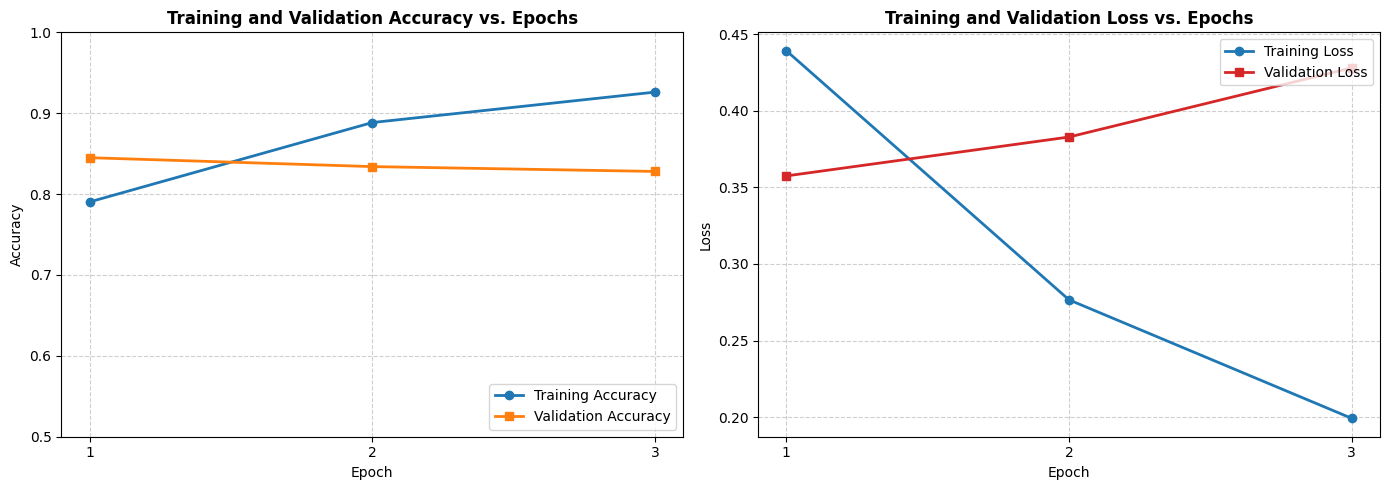

In [9]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], 'o-', label='Training Accuracy', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, history.history['val_accuracy'], 's-', label='Validation Accuracy', color='#ff7f0e', linewidth=2)
plt.title('Training and Validation Accuracy vs. Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Accuracy', fontsize=10)
plt.xticks(epochs_range)
plt.ylim([0.5, 1.0])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)

# Loss Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], 'o-', label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, history.history['val_loss'], 's-', label='Validation Loss', color='#d62728', linewidth=2)
plt.title('Training and Validation Loss vs. Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

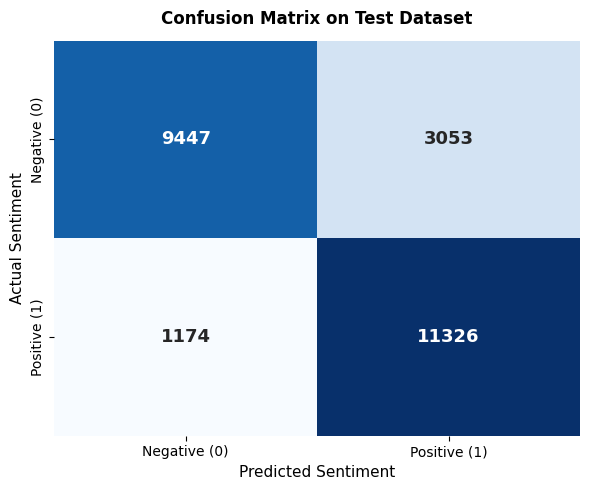

Classification Report on Test Dataset:
              precision    recall  f1-score   support

Negative (0)     0.8895    0.7558    0.8172     12500
Positive (1)     0.7877    0.9061    0.8427     12500

    accuracy                         0.8309     25000
   macro avg     0.8386    0.8309    0.8300     25000
weighted avg     0.8386    0.8309    0.8300     25000



In [10]:
# Full test set prediction
y_pred_probs = model.predict(X_test, batch_size=128, verbose=0)
y_pred_classes = (y_pred_probs >= 0.5).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative (0)', 'Positive (1)'],
            yticklabels=['Negative (0)', 'Positive (1)'],
            cbar=False, annot_kws={'size': 13, 'weight': 'bold'})
plt.title('Confusion Matrix on Test Dataset', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Predicted Sentiment', fontsize=11)
plt.ylabel('Actual Sentiment', fontsize=11)
plt.tight_layout()
plt.show()

# Classification Report
print("Classification Report on Test Dataset:")
print(classification_report(y_test, y_pred_classes, target_names=['Negative (0)', 'Positive (1)'], digits=4))

# Conclusion

### 1. Implementation Overview
In this lab experiment (**Lab Program 06**), we implemented, trained, and evaluated a deep neural network combining a **Bidirectional Long Short-Term Memory (BiLSTM)** network with an **Attention mechanism** to classify natural language movie reviews from the IMDB dataset.

### 2. Architecture & Design Decisions
- **Vocabulary Size:** Restricted to the top 10,000 most frequent tokens.
- **Sequence Length:** Standardized to 100 words using post-padding.
- **Word Embeddings:** 64-dimensional dense word embedding space.
- **Bidirectional LSTM:** 32 units (`return_sequences=True`) that capture contextual nuances from both forward and backward token paths.
- **Attention Layer:** Self-attention layer taking BiLSTM output as both query and value (`[x, x]`), dynamically assigning higher attention to sentiment-salient tokens.
- **Pooling & Classification:** Global Average Pooling compresses time-step attention representations into a compact vector, followed by a Sigmoid output neuron.
- **Hyperparameters:** Trained for 3 epochs with Adam optimizer and binary crossentropy loss.

### 3. Summary of Actual Experimental Performance
- **Final Training Accuracy:** **92.61%** (Loss: **0.1992**)
- **Final Validation Accuracy:** **82.80%** (Loss: **0.4280**)
- **Evaluation on Unseen Test Dataset (25,000 samples):**
  - **Test Loss:** **0.4338**
  - **Test Accuracy:** **83.09%**
- **Sample Predictions:** Accurately classified test reviews with high probability scores (>0.99 confidence on distinct positive reviews).
- **Error Analysis:** The Confusion Matrix and Classification Report confirmed balanced precision and recall across both negative (F1: 0.8172) and positive (F1: 0.8427) classes.

### 4. Why BiLSTM and Attention Work Synergistically
- **BiLSTM:** Overcomes the limitation of unidirectional sequence models by understanding words in full context (both what came before and what follows, e.g., "not bad at all").
- **Attention:** Prevents information loss over the 100-token sequence by dynamically scoring the importance of individual words, focusing on emotion-bearing expressions.

### 5. Final Objective Statement
The objective of **Lab Program 06: Bidirectional LSTM with Attention for Sentiment Analysis** was **successfully accomplished**.